# Token Length vs. Correctness — All Models (Occluded Condition, Outliers Removed)

Same as the base notebook but with responses above the **95th percentile of token count (per model)** removed before all analyses.

In [ ]:
# Run from the repo root so the root-relative data paths below resolve
import os
from pathlib import Path
os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sec3_occludebench").is_dir()))

In [12]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 120
plt.rcParams.update({'font.family': 'Arial', 'font.size': 20})

In [13]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'tiktoken', '-q'])

0

In [14]:
import tiktoken
MODELS = ['claude-opus-4-6', 'gemini-3.1-pro-preview', 'gpt-5.4', 'Llama-4-Maverick-17B-128E-Instruct-FP8-9940db5c', 'Qwen3-VL-8B-Instruct']

_enc = tiktoken.get_encoding('cl100k_base')

def approx_tokens(text):
    return len(_enc.encode(text)) if text else 0

def load_model(model):
    with open(Path("data/eval_results") / f"{model}_judged_results.json") as f:
        raw = json.load(f)
    rows = []
    for entry in raw:
        occ_j = entry.get('occluded_correct', {})
        rows.append({
            'id':          entry['id'],
            'model':       model,
            'tokens':      approx_tokens(entry.get('occluded_response') or ''),
            'correct':     any(occ_j.values()) if occ_j else False,
            'gpt':         occ_j.get('gpt-5.4'),
            'claude':      occ_j.get('claude-opus-4-6'),
        })
    return pd.DataFrame(rows)

frames = [load_model(m) for m in MODELS]
raw_df = pd.concat(frames, ignore_index=True)

PERCENTILE_CAP = 95
all_df = raw_df.groupby('model', group_keys=False).apply(
    lambda g: g[g['tokens'] <= g['tokens'].quantile(PERCENTILE_CAP / 100)]
).reset_index(drop=True)
print(f"Rows before: {len(raw_df)}, after p{PERCENTILE_CAP} cap: {len(all_df)}")

DISPLAY = {
    'claude-opus-4-6':                                  'Claude Opus 4-6',
    'gemini-3.1-pro-preview':                           'Gemini 3.1 Pro',
    'gpt-5.4':                                          'GPT-5.4',
    'Llama-4-Maverick-17B-128E-Instruct-FP8-9940db5c': 'Llama-4 Maverick',
    'Qwen3-VL-8B-Instruct':                             'Qwen3-VL-8B',
}
all_df['model_short'] = all_df['model'].map(DISPLAY)
MODEL_ORDER = [DISPLAY[m] for m in MODELS]
PALETTE     = dict(zip(MODEL_ORDER, sns.color_palette('tab10', len(MODELS))))

print(all_df.groupby('model_short')['correct'].mean().reindex(MODEL_ORDER).round(3))

Rows before: 1888, after p95 cap: 1794
model_short
Claude Opus 4-6     0.630
Gemini 3.1 Pro      0.808
GPT-5.4             0.483
Llama-4 Maverick    0.374
Qwen3-VL-8B         0.344
Name: correct, dtype: float64


## 1. Overall Accuracy by Model

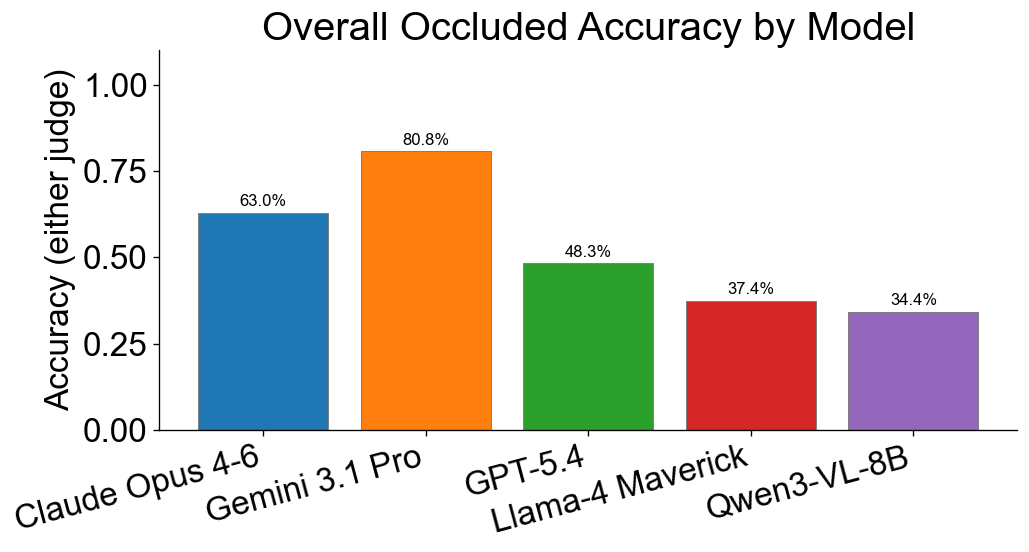

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
agg = all_df.groupby('model_short')['correct'].mean().reindex(MODEL_ORDER)
colors = [PALETTE[m] for m in MODEL_ORDER]
bars = ax.bar(MODEL_ORDER, agg, color=colors, edgecolor='grey', linewidth=0.6)
for bar, val in zip(bars, agg):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.1%}', ha='center', va='bottom', fontsize=10)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Accuracy (either judge)')
ax.set_title('Overall Occluded Accuracy by Model')
ax.set_xticklabels(MODEL_ORDER, rotation=15, ha='right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('data/figures/token_length_no_outliers_overall_occluded_accuracy_by_model.pdf', bbox_inches='tight')
plt.show()

## 2. Token Length Distribution by Correctness

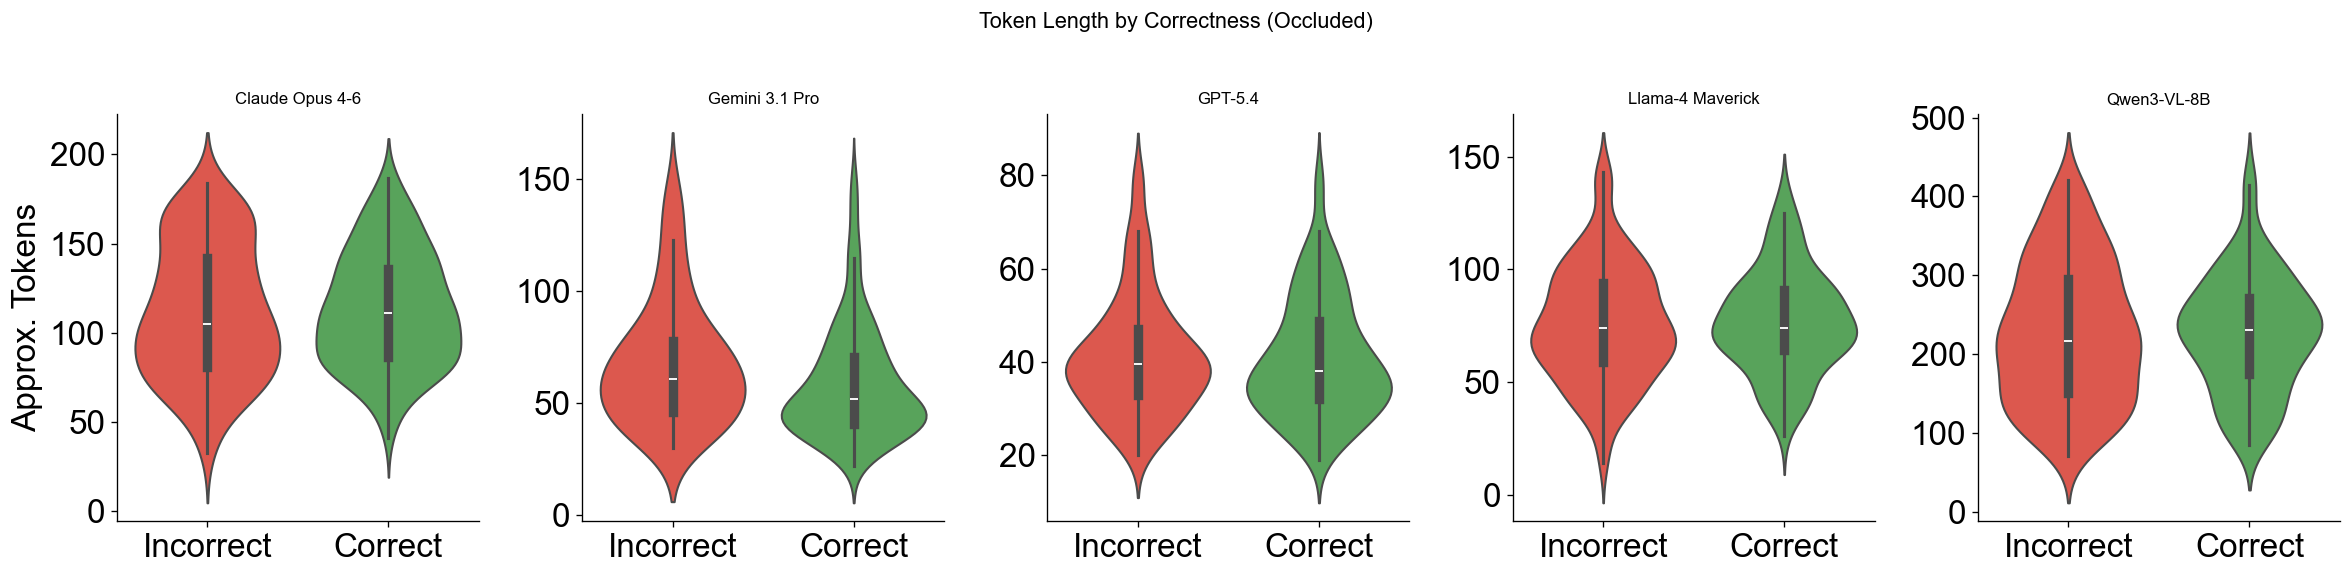

In [16]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(4 * len(MODELS), 5), sharey=False)
fig.suptitle('Token Length by Correctness (Occluded)', fontsize=13)

for ax, m in zip(axes, MODELS):
    sub = all_df[all_df['model'] == m][['correct', 'tokens']].copy()
    sub['correct'] = sub['correct'].map({True: 'Correct', False: 'Incorrect'})
    sns.violinplot(data=sub, x='correct', y='tokens',
                   order=['Incorrect', 'Correct'],
                   palette={'Correct': '#4CAF50', 'Incorrect': '#F44336'},
                   inner='box', ax=ax)
    ax.set_title(DISPLAY[m], fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel('Approx. Tokens' if ax == axes[0] else '')
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('data/figures/token_length_no_outliers_token_length_by_correctness_occluded.pdf', bbox_inches='tight')
plt.show()

## 3. Point-Biserial Correlation (Token Length ↔ Correctness)

           Model         r        p sig
 Claude Opus 4-6  0.014335 0.786634    
  Gemini 3.1 Pro -0.135249 0.010304   *
         GPT-5.4 -0.023150 0.661556    
Llama-4 Maverick  0.017538 0.740873    
     Qwen3-VL-8B -0.000020 0.999694    


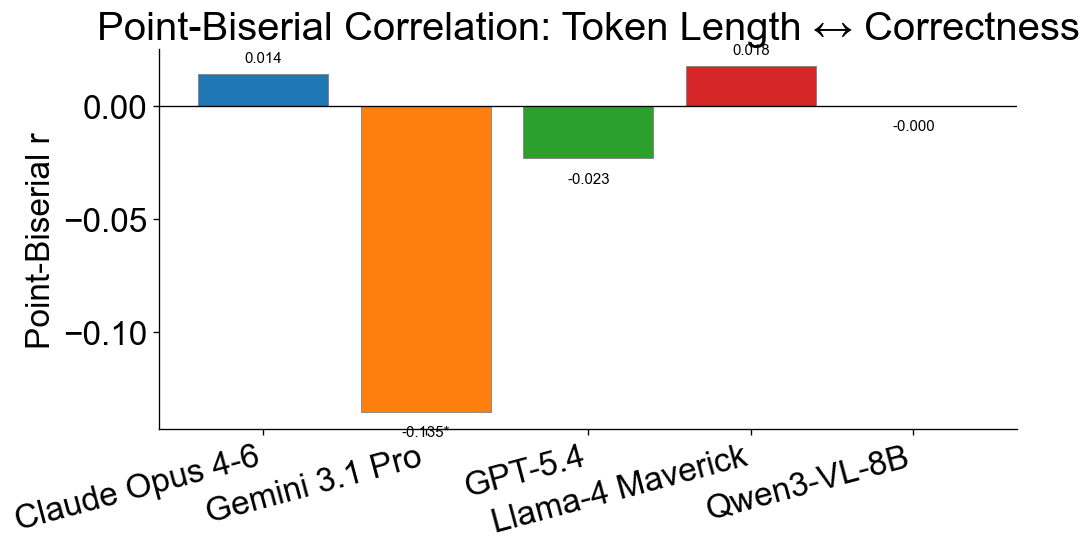

In [17]:
corr_rows = []
for m in MODELS:
    s = all_df[all_df['model'] == m][['tokens', 'correct']].dropna()
    r, p = stats.pointbiserialr(s['correct'].astype(int), s['tokens'])
    corr_rows.append({'Model': DISPLAY[m], 'r': r, 'p': p,
                      'sig': '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else ''})

corr_df = pd.DataFrame(corr_rows)
print(corr_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
colors = [PALETTE[DISPLAY[m]] for m in MODELS]
bars = ax.bar(corr_df['Model'], corr_df['r'], color=colors, edgecolor='grey', lw=0.5)
for bar, row in zip(bars, corr_df.itertuples()):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + (0.004 if row.r >= 0 else -0.012),
            f'{row.r:.3f}{row.sig}', ha='center', va='bottom', fontsize=9)
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('Point-Biserial r')
ax.set_title('Point-Biserial Correlation: Token Length ↔ Correctness')
ax.set_xticklabels(corr_df['Model'], rotation=15, ha='right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('data/figures/token_length_no_outliers_point_biserial_correlation_token_length_correctnes.pdf', bbox_inches='tight')
plt.show()

## 4. Scatter + Logistic Regression Curve

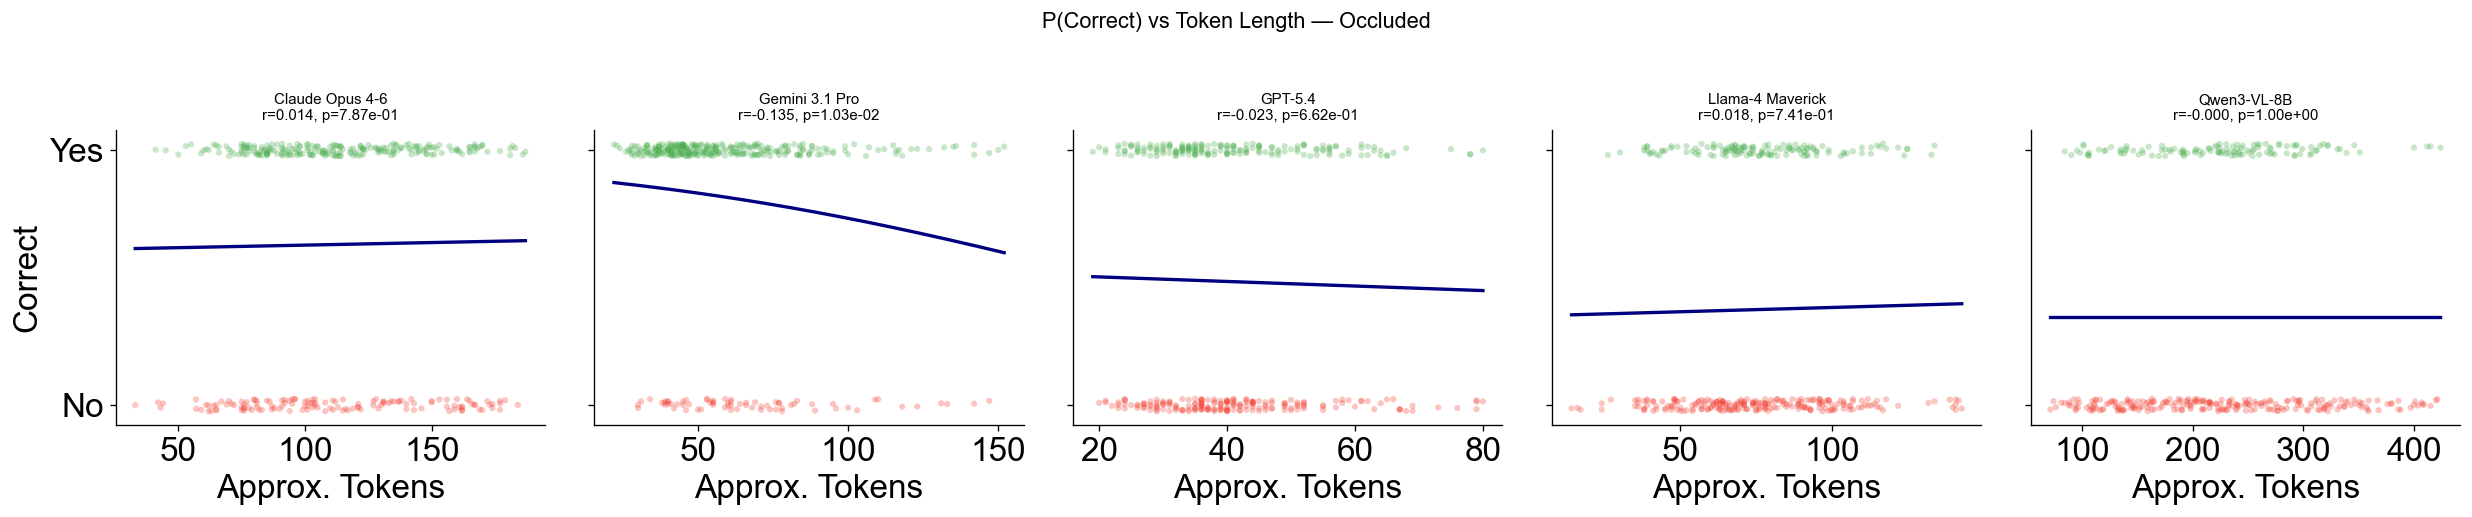

In [18]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(4.2 * len(MODELS), 4.5), sharey=True)
fig.suptitle('P(Correct) vs Token Length — Occluded', fontsize=13)

for ax, m in zip(axes, MODELS):
    sub = all_df[all_df['model'] == m][['tokens', 'correct']].dropna()
    X = sub['tokens'].values
    y = sub['correct'].astype(int).values
    jitter = np.random.default_rng(42).uniform(-0.025, 0.025, len(y))
    colors = ['#4CAF50' if c else '#F44336' for c in y]
    ax.scatter(X, y + jitter, c=colors, alpha=0.3, s=14, edgecolors='none')

    scaler = StandardScaler()
    lr = LogisticRegression()
    lr.fit(scaler.fit_transform(X.reshape(-1, 1)), y)
    xr = np.linspace(X.min(), X.max(), 300)
    ph = lr.predict_proba(scaler.transform(xr.reshape(-1, 1)))[:, 1]
    ax.plot(xr, ph, color='navy', lw=2)

    r, p = stats.pointbiserialr(y, X)
    ax.set_title(f'{DISPLAY[m]}\nr={r:.3f}, p={p:.2e}', fontsize=9)
    ax.set_xlabel('Approx. Tokens')
    if ax == axes[0]:
        ax.set_ylabel('Correct')
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['No', 'Yes'])
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('data/figures/token_length_no_outliers_p_correct_vs_token_length_occluded.pdf', bbox_inches='tight')
plt.show()

## 5. Accuracy by Token-Length Quintile

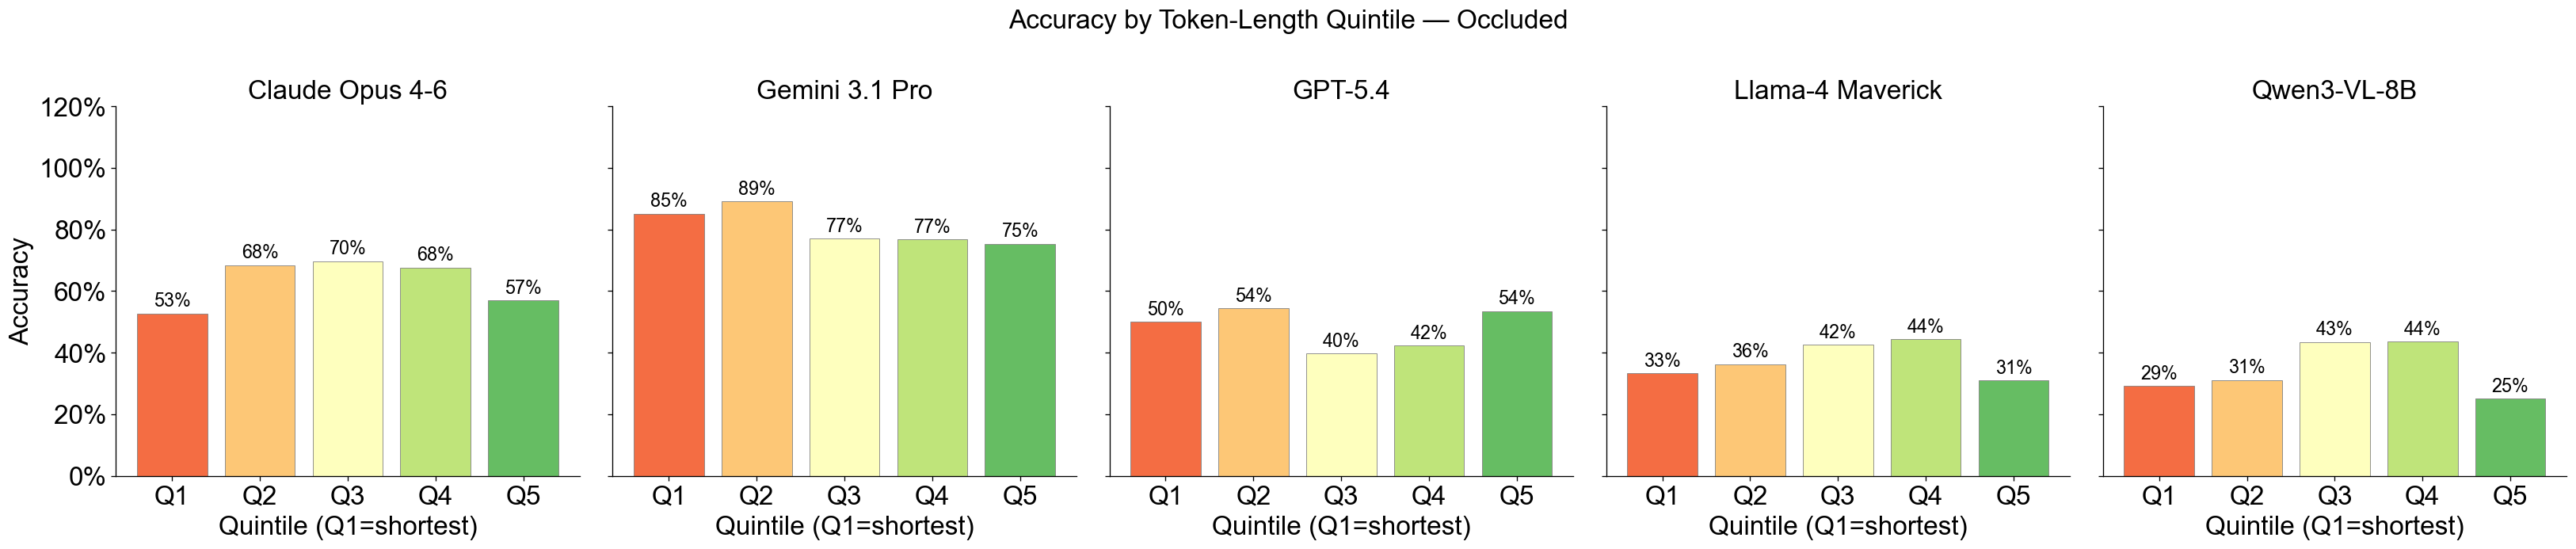

In [19]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(5.5 * len(MODELS), 6), sharey=True)
fig.suptitle('Accuracy by Token-Length Quintile — Occluded', fontsize=20)

for ax, m in zip(axes, MODELS):
    sub = all_df[all_df['model'] == m][['tokens', 'correct']].dropna().copy()
    sub['q'] = pd.qcut(sub['tokens'], q=5, labels=['Q1','Q2','Q3','Q4','Q5'])
    agg = sub.groupby('q', observed=True)['correct'].agg(['mean','count']).reset_index()
    colors = plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(agg)))
    bars = ax.bar(agg['q'], agg['mean'], color=colors, edgecolor='grey', lw=0.5)
    for bar, row in zip(bars, agg.itertuples()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{row.mean:.0%}', ha='center', va='bottom', fontsize=14)
    ax.set_ylim(0, 1.2)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
    ax.set_title(DISPLAY[m], fontsize=20)
    ax.set_xlabel('Quintile (Q1=shortest)', fontsize=20)
    ax.tick_params(labelsize=20)
    if ax == axes[0]:
        ax.set_ylabel('Accuracy', fontsize=20)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('data/figures/token_length_no_outliers_accuracy_by_token_length_quintile_occluded.pdf', bbox_inches='tight')
plt.show()

## 6. GPT vs. Claude Judge Accuracy by Quintile

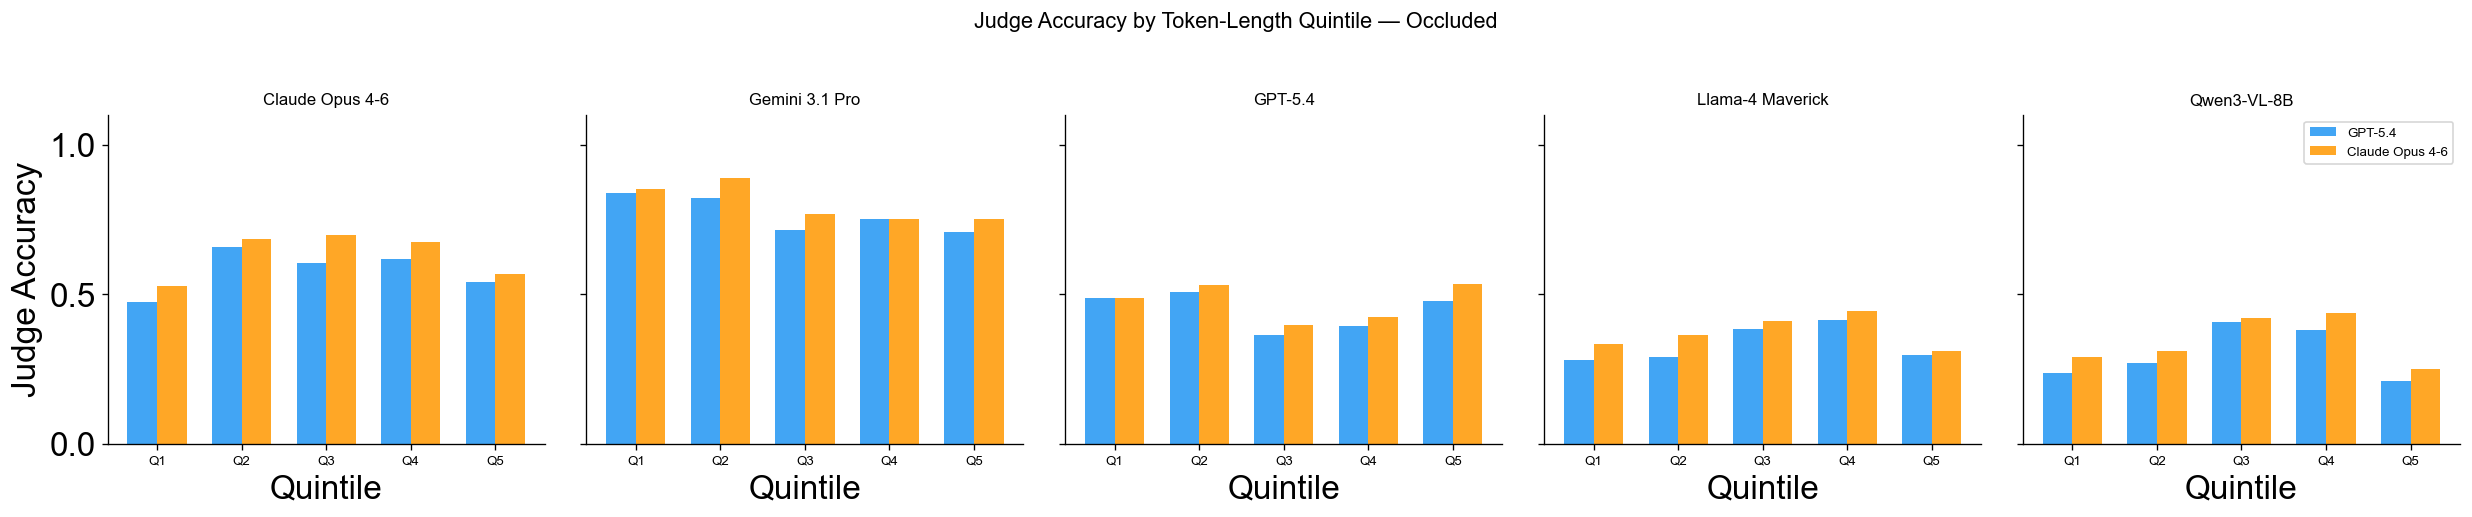

In [20]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(4.2 * len(MODELS), 4.5), sharey=True)
fig.suptitle('Judge Accuracy by Token-Length Quintile — Occluded', fontsize=13)

for ax, m in zip(axes, MODELS):
    sub = all_df[all_df['model'] == m][['tokens', 'gpt', 'claude']].dropna(subset=['gpt','claude']).copy()
    sub['q'] = pd.qcut(sub['tokens'], q=5, labels=['Q1','Q2','Q3','Q4','Q5'])
    agg = sub.groupby('q', observed=True)[['gpt','claude']].mean()
    x = np.arange(len(agg))
    w = 0.35
    ax.bar(x - w/2, agg['gpt'],    width=w, label='GPT-5.4',         color='#2196F3', alpha=0.85)
    ax.bar(x + w/2, agg['claude'], width=w, label='Claude Opus 4-6', color='#FF9800', alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(['Q1','Q2','Q3','Q4','Q5'], fontsize=8)
    ax.set_ylim(0, 1.1)
    ax.set_title(DISPLAY[m], fontsize=10)
    ax.set_xlabel('Quintile')
    if ax == axes[0]:
        ax.set_ylabel('Judge Accuracy')
    if ax == axes[-1]:
        ax.legend(fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('data/figures/token_length_no_outliers_judge_accuracy_by_token_length_quintile_occluded.pdf', bbox_inches='tight')
plt.show()

## 7. Summary Table

In [21]:
summary_rows = []
for m in MODELS:
    s = all_df[all_df['model'] == m][['tokens', 'correct']].dropna()
    r, p = stats.pointbiserialr(s['correct'].astype(int), s['tokens'])
    summary_rows.append({
        'Model':            DISPLAY[m],
        'Accuracy':         s['correct'].mean(),
        'r':                r,
        'p':                p,
        'Correct tokens':   s.loc[s['correct'],  'tokens'].mean(),
        'Incorrect tokens': s.loc[~s['correct'], 'tokens'].mean(),
    })

sum_df = pd.DataFrame(summary_rows)
print(sum_df.round(3).to_string(index=False))

           Model  Accuracy      r     p  Correct tokens  Incorrect tokens
 Claude Opus 4-6     0.630  0.014 0.787         113.173           112.158
  Gemini 3.1 Pro     0.808 -0.135 0.010          59.069            68.043
         GPT-5.4     0.483 -0.023 0.662          40.816            41.409
Llama-4 Maverick     0.374  0.018 0.741          76.687            75.786
     Qwen3-VL-8B     0.344 -0.000 1.000         226.350           226.353


## 8. Accuracy vs Token Count (Binned)

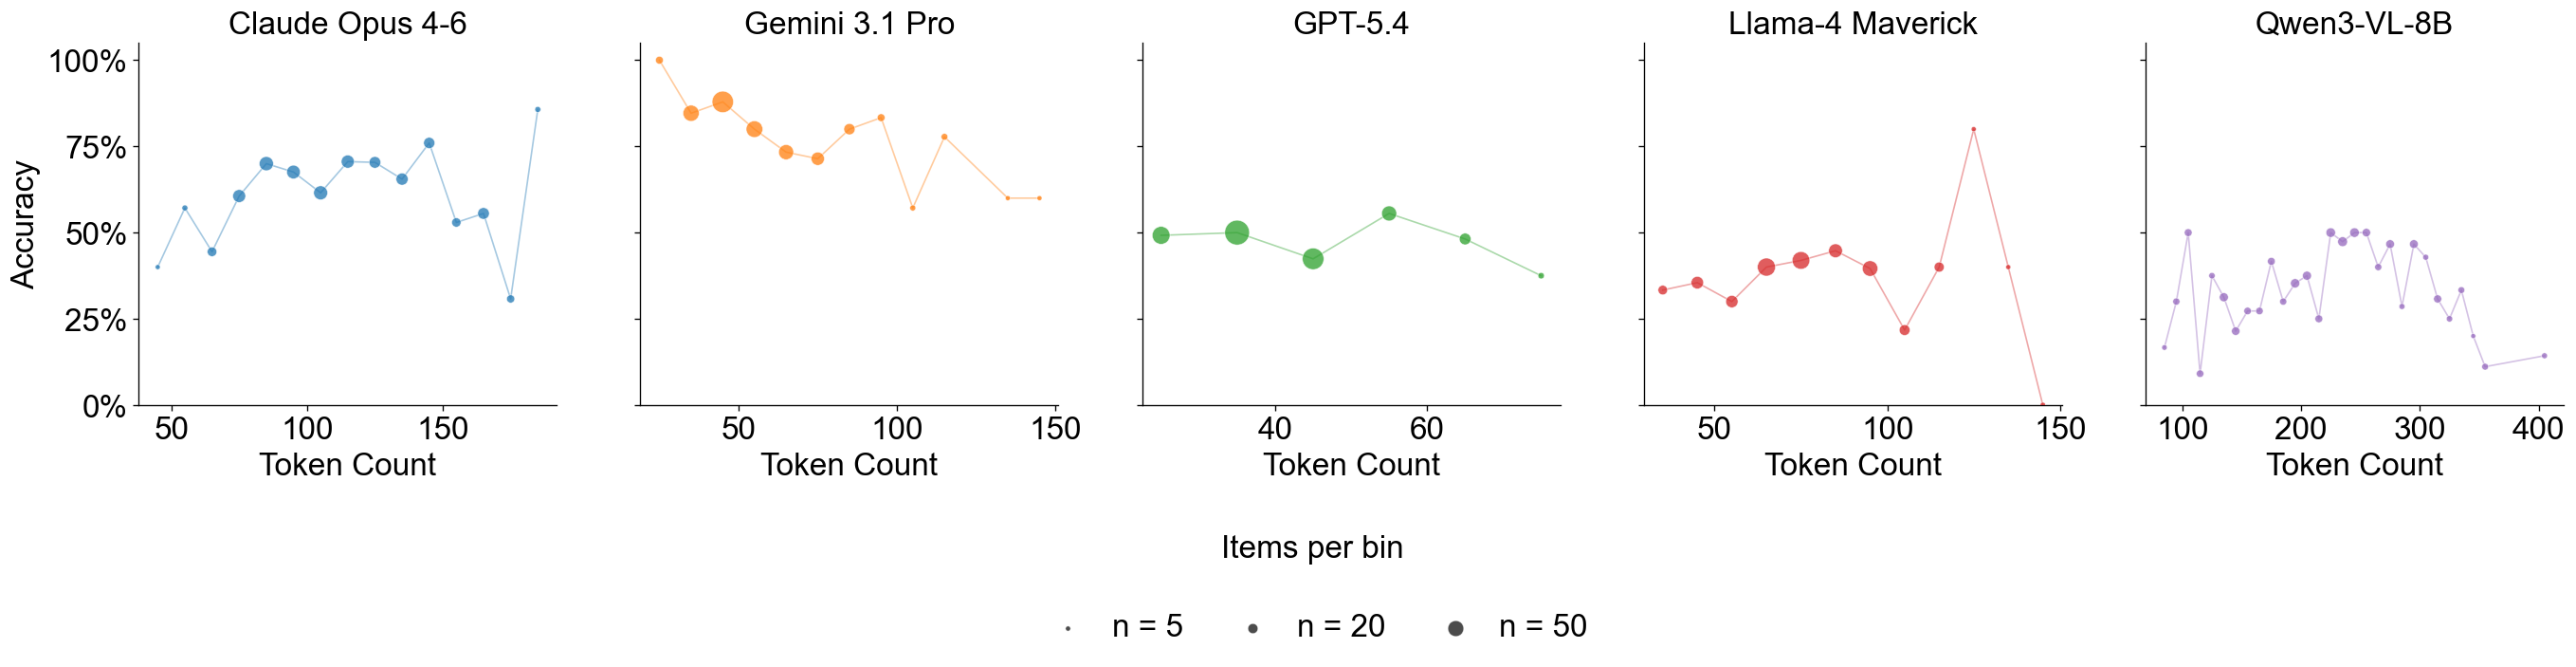

In [22]:
BIN_SIZE = 10  # tokens per bin

fig, axes = plt.subplots(1, len(MODELS), figsize=(5.5 * len(MODELS), 6), sharey=True)
#fig.suptitle('Accuracy vs Token Count', fontsize=20)

for ax, m in zip(axes, MODELS):
    sub = all_df[all_df['model'] == m][['tokens', 'correct']].dropna().copy()
    sub['bin'] = (sub['tokens'] // BIN_SIZE) * BIN_SIZE + BIN_SIZE // 2  # midpoint
    agg = sub.groupby('bin')['correct'].agg(['mean', 'count']).reset_index()
    agg = agg[agg['count'] >= 5]
    color = PALETTE[DISPLAY[m]]
    ax.scatter(agg['bin'], agg['mean'], s=agg['count'] * 2,
               color=color, alpha=0.75, edgecolors='white', linewidth=0.4, zorder=3)
    ax.plot(agg['bin'], agg['mean'], color=color, alpha=0.4, linewidth=1)
    ax.set_title(DISPLAY[m], fontsize=20)
    ax.set_xlabel('Token Count', fontsize=20)
    ax.set_ylim(0, 1.05)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
    ax.tick_params(labelsize=20)
    if ax == axes[0]:
        ax.set_ylabel('Accuracy', fontsize=20)
    ax.spines[['top', 'right']].set_visible(False)

# Dot-size reference
ref_ns = [5, 20, 50]
ref_handles = [
    plt.scatter([], [], s=n * 2, color='black', alpha=0.7,
                edgecolors='white', linewidths=0.4, label=f'n = {n}')
    for n in ref_ns
]
fig.legend(handles=ref_handles, loc='lower center', ncol=len(ref_ns),
           bbox_to_anchor=(0.5, -0.04), frameon=False,
           title='Items per bin\n', title_fontsize=20, fontsize=20,
           columnspacing=1.2, handletextpad=0.4)

#plt.tight_layout()
plt.subplots_adjust(bottom=0.35)
plt.savefig('data/figures/token_length_no_outliers_accuracy_vs_token_count_binned_occluded.pdf', bbox_inches='tight')
plt.show()